## Graph 1: Frequency of AI Usage Across Study Activities

**Graph Type:** Heatmap

**Description:** This heatmap compares how frequently students use AI for different study activities. The rows represent study activities, while the columns represent AI usage frequency levels. Darker blue colors indicate higher percentages of students selecting a response.

**Hypothesis:** We think students are more likely to use AI frequently for asking questions, finding definitions, and reviewing mistakes in their work than for completing coding, STEM homework, or writing-based assignments.

**Takeaway:** Students report using AI very often for asking questions (60.3%), reviewing calculation mistakes (58.6%), and reviewing written mistakes (48.3%). In contrast, fewer students report using AI very often for completing STEM homework (19.0%) and writing assignments (17.2%). This suggests that students are more likely to use AI for understanding concepts and reviewing their mistakes than for completing assignments directly.

**Status:** Graph completed.

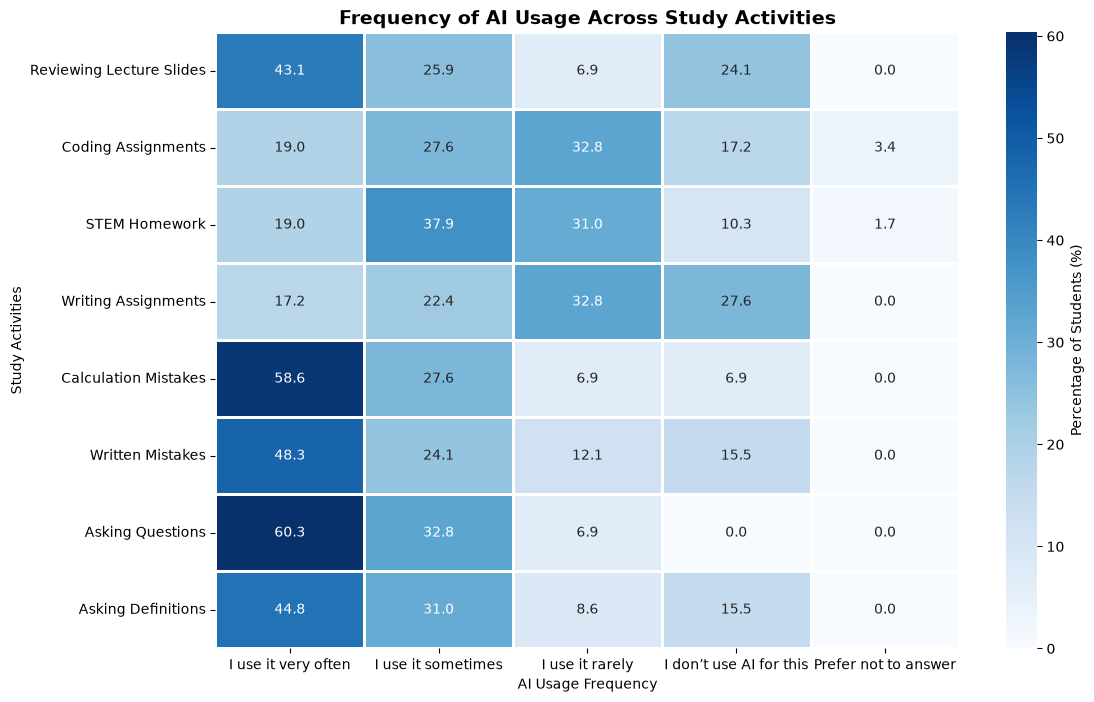

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

survey_df = pd.read_csv("survey.csv")
# create crosstable that limit x-axis as "i don't use AI for this, i use it rarelly, etc"
# y-axis as types of questions: "reviewing lecture slides, doing homework for STEM related subjects, etc"
study_df = survey_df.loc[:, "How often do you use AI for the following:\n [Reviewing Lecture slides]": "How often do you use AI for the following:\n [Asking for definitions]"]
study_df["How often do you use AI for the following:\n [Reviewing Lecture slides]"].value_counts()

# Count responses for each study activity
lecture = study_df.iloc[:, 0].value_counts()
coding = study_df.iloc[:, 1].value_counts()
stem = study_df.iloc[:, 2].value_counts()
writing = study_df.iloc[:, 3].value_counts()
calculation = study_df.iloc[:, 4].value_counts()
written_review = study_df.iloc[:, 5].value_counts()
questions = study_df.iloc[:, 6].value_counts()
definitions = study_df.iloc[:, 7].value_counts()



# Combine response counts into one DataFrame
cross_survey = pd.DataFrame({
    "Reviewing Lecture Slides": lecture,
    "Coding Assignments": coding,
    "STEM Homework": stem,
    "Writing Assignments": writing,
    "Calculation Mistakes": calculation,
    "Written Mistakes": written_review,
    "Asking Questions": questions,
    "Asking Definitions": definitions
}).T.fillna(0)

# Reorder the response categories
response_order = ["I use it very often", "I use it sometimes", "I use it rarely", "I don’t use AI for this", "Prefer not to answer"]

cross_survey = cross_survey.reindex(columns=response_order, fill_value=0)

# Calculate percentages
percentage_survey = (cross_survey.div(cross_survey.sum(axis=1), axis=0) * 100)

# Create a heatmap
# Set figure size for better readability
plt.figure(figsize=(12, 8))

# cmap='Blues': Darker blue represents a higher percentage
# annot=True: Displays the percentages in each cell
# fmt='.1f': Shows percentages with 1 decimal place
# linewidths=1: Adds spacing between cells
sns.heatmap(percentage_survey, cmap='Blues', annot=True, fmt='.1f',
            linewidths=1, cbar_kws={'label': 'Percentage of Students (%)'})

# Add title and labels
plt.title('Frequency of AI Usage Across Study Activities', fontsize=14, fontweight='bold')
plt.xlabel('AI Usage Frequency')
plt.ylabel('Study Activities')
plt.show()

